# Phase 1 Task B — ConvNeXt-Tiny × 3 Seeds

**Model:** ConvNeXt-Tiny
**Seeds:** 42, 123, 456
**Batch:** 32
**Output:** wandb `woodbench-taskB`

Chạy notebook này trên 1 GPU (vast.ai).

In [1]:
from pathlib import Path
NOTEBOOK = Path("__file__").resolve()
ROOT = NOTEBOOK
for _ in range(10):
    ROOT = ROOT.parent
    if (ROOT / "pyproject.toml").exists() or (ROOT / ".git").exists(): break
import sys, os
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
print(f"[ROOT] {ROOT}")

[ROOT] /workspace/woodbench


In [2]:
# Load .env for API keys
from dotenv import load_dotenv
dotenv_path = ROOT / ".env"
load_dotenv(dotenv_path)
print(f"[.env] Loaded from {dotenv_path}")

import subprocess, sys
for pkg in ["timm", "albumentations", "scikit-learn", "seaborn", "wandb", "ptflops", "python-dotenv"]:
    try: __import__(pkg.replace("-", "_"))
    except: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

os.environ.setdefault("WANDB_API_KEY", os.getenv("WANDB_API_KEY", ""))
os.environ.setdefault("HF_TOKEN", os.getenv("HF_TOKEN", ""))
print(f"[wandb] API key: {'set' if os.getenv('WANDB_API_KEY') else 'MISSING'}")
print(f"[HF] token: {'set' if os.getenv('HF_TOKEN') else 'MISSING'}")

python-dotenv could not parse statement starting at line 4
python-dotenv could not parse statement starting at line 6
python-dotenv could not parse statement starting at line 7


[.env] Loaded from /workspace/woodbench/.env


[wandb] API key: set
[HF] token: set


In [3]:
# Download data from HuggingFace
HF_REPO = "ny0g507h3p/wood-task-B"
DATA_ROOT = ROOT / "data" / "task-B"

if not (DATA_ROOT / "train").exists():
    print(f"[HF] Downloading dataset to {DATA_ROOT}...")
    from huggingface_hub import login, snapshot_download
    token = os.getenv("HF_TOKEN", "")
    if token:
        login(token=token)
        print("[HF] Logged in")
    else:
        print("[HF] No token — trying public access")
    snapshot_download(
        repo_id=HF_REPO,
        repo_type="dataset",
        local_dir=str(DATA_ROOT),
        ignore_patterns=["*.md", "README*"],
    )
    print("[HF] Download complete")
else:
    print(f"[Data] Found at {DATA_ROOT}")

# Verify
train_dir = DATA_ROOT / "train"
if not train_dir.exists():
    raise FileNotFoundError(f"[ERROR] train/ not found in {DATA_ROOT}. Dataset download failed.")
classes = sorted([d.name for d in train_dir.iterdir() if d.is_dir()])
print(f"[Data] {len(classes)} classes: {classes[:3]}...")
print(f"[Data] Train samples: {sum(1 for _ in train_dir.rglob('*.jpg')) + sum(1 for _ in train_dir.rglob('*.png'))}")

[Data] Found at /workspace/woodbench/data/task-B
[Data] 20 classes: ['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris']...
[Data] Train samples: 3973


In [4]:
from src.data import get_dataloaders
# num_workers=4 to avoid multiprocessing issues on vast.ai
tl, vl, testl = get_dataloaders(str(DATA_ROOT), batch_size=32, num_workers=4, task="taskB")
print(f"[Data] Train={len(tl.dataset)}, Val={len(vl.dataset)}, Test={len(testl.dataset)}")
print(f"[Data] Classes={len(tl.dataset.classes)}")

[Data] Train=3973, Val=933, Test=924
[Data] Classes=20


In [5]:
import wandb, torch, numpy as np
from src.models import create_model
from src.train import TrainingEngine, create_optimizer, create_scheduler, create_loss_function
from src.utils import set_seed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[Device] {DEVICE}")

[Device] cuda


In [6]:
def train_one(backbone, seed, data_root, batch_size=32, epochs=50):
    set_seed(seed)
    output_dir = ROOT / "data" / "experiments" / "taskB" / backbone / f"seed_{seed}"
    output_dir.mkdir(parents=True, exist_ok=True)

    # num_workers=4 for papermill compatibility
    train_loader, val_loader, _ = get_dataloaders(
        data_root=data_root, batch_size=batch_size, num_workers=4, task="taskB")
    num_classes = len(train_loader.dataset.classes)
    print(f"[{backbone} s{seed}] train={len(train_loader.dataset)}, classes={num_classes}")

    run = wandb.init(project="woodbench-taskB", name=f"{backbone}_s{seed}",
        config={"backbone": backbone, "seed": seed, "epochs": epochs,
                "batch_size": batch_size, "num_classes": num_classes,
                "lr_head": 1e-4, "lr_backbone": 1e-5,
                "label_smoothing": 0.1, "scheduler": "cosine", "amp": True},
        dir=str(output_dir))

    model = create_model(backbone, num_classes=num_classes, pretrained=True)
    optimizer = create_optimizer(model, lr=1e-4, weight_decay=1e-4, backbone_lr=1e-5)
    scheduler = create_scheduler(optimizer, epochs=epochs, scheduler_type="cosine")
    criterion = create_loss_function("label_smoothing", label_smoothing=0.1)

    engine = TrainingEngine(model=model, train_loader=train_loader, val_loader=val_loader,
        optimizer=optimizer, scheduler=scheduler, criterion=criterion,
        device=DEVICE, use_amp=True)
    result = engine.fit(epochs=epochs, output_dir=output_dir,
                       name=f"{backbone}_seed{seed}", save_best_only=True,
                       early_stopping_patience=10)
    run.finish()
    print(f"[{backbone} s{seed}] val_acc={result['best_val_acc']:.2f}%")
    return result

In [7]:
# ── Cell 7: Training Loop (3 seeds) ──────────────────────────────────────────
SEEDS = [42, 123, 456]
results = {}

for seed in SEEDS:
    print(f"\n{'='*60}")
    print(f"ConvNeXt-Tiny | seed={seed} ({SEEDS.index(seed)+1}/{len(SEEDS)})")
    print(f"{'='*60}")
    results[seed] = train_one("convnext_tiny", seed, str(DATA_ROOT), batch_size=32, epochs=50)

print("\n" + "="*60)
print("ConvNeXt-Tiny — Summary")
for seed, res in results.items():
    print(f"  seed={seed}: {res['best_val_acc']:.2f}%")
accs = [r['best_val_acc'] for r in results.values()]
print(f"  Mean: {np.mean(accs):.2f}% ± {np.std(accs):.2f}%")


ConvNeXt-Tiny | seed=42 (1/3)


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


[convnext_tiny s42] train=3973, classes=20


wandb: Currently logged in as: ny0g507h3p (ny0g507h3p_) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch 1/50 | Train Loss: 3.2002, Acc: 7.06% | Val Loss: 3.2637, Acc: 5.89% | LR: 2.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to convnext_tiny_seed42_best.pth (Val Acc: 5.89%)


Epoch 2/50 | Train Loss: 1.0612, Acc: 85.81% | Val Loss: 0.7182, Acc: 97.64% | LR: 4.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to convnext_tiny_seed42_best.pth (Val Acc: 97.64%)


... (66 outputs left out)

Epoch 18/50 | Train Loss: 0.5946, Acc: 100.00% | Val Loss: 0.5958, Acc: 100.00% | LR: 8.08e-05[EarlyStop 8/10]


Epoch 19/50 | Train Loss: 0.5945, Acc: 100.00% | Val Loss: 0.5948, Acc: 100.00% | LR: 7.80e-05[EarlyStop 9/10]


Epoch 20/50 | Train Loss: 0.5945, Acc: 99.97% | Val Loss: 0.5984, Acc: 99.89% | LR: 7.50e-05[EarlyStop 10/10]

[EarlyStopping] No improvement for 10 epochs. Stopping at epoch 20.


[convnext_tiny s456] val_acc=100.00%

ConvNeXt-Tiny — Summary
  seed=42: 100.00%
  seed=123: 100.00%
  seed=456: 100.00%
  Mean: 100.00% ± 0.00%


[CM] 20 classes: ['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris', 'Calocedrus sp', 'Chamaecyparis obtusa', 'Cryptomeria japonica', 'Cunninghamia lanceolata', 'Cupressus funebris (Cupressus pendula)', 'Fokienia hodginsii', 'Picea glauca', 'Pinus cernua', 'Pinus dalatensis', 'Pinus krempfii', 'Pinus radiata', 'Pinus sp', 'Podocarpus pilgeri', 'Pseudotsuga brevifolia', 'Taxus wallichiana', 'Thujopsis dolabrata', 'Xanthocyparis vietnamensis']
[CM] Loading: /workspace/woodbench/data/experiments/taskB/convnext_tiny/seed_42/convnext_tiny_seed42_best.pth
[CM s42] Acc=99.57%  F1=99.58%  Prec=99.60%  Rec=99.57%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=98.08%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=100.00%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=100.00%
  Cupressus funebris (Cupressus pendula): F1=100.00%
  Fokienia hodginsii: F1=100.00%
  Picea glauca: F1=97.83%
  Pinus cernua:

test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Loading: /workspace/woodbench/data/experiments/taskB/convnext_tiny/seed_123/convnext_tiny_seed123_best.pth
[CM s123] Acc=99.78%  F1=99.79%  Prec=99.79%  Rec=99.80%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=99.01%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=100.00%
  Chamaecyparis obtusa: F1=98.97%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=100.00%
  Cupressus funebris (Cupressus pendula): F1=100.00%
  Fokienia hodginsii: F1=100.00%
  Picea glauca: F1=98.90%
  Pinus cernua: F1=100.00%
  Pinus dalatensis: F1=100.00%
  Pinus krempfii: F1=100.00%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=100.00%
  Podocarpus pilgeri: F1=100.00%
  Pseudotsuga brevifolia: F1=100.00%
  Taxus wallichiana: F1=100.00%
  Thujopsis dolabrata: F1=98.97%
  Xanthocyparis vietnamensis: F1=100.00%


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Loading: /workspace/woodbench/data/experiments/taskB/convnext_tiny/seed_456/convnext_tiny_seed456_best.pth
[CM s456] Acc=99.68%  F1=99.68%  Prec=99.68%  Rec=99.68%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=100.00%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=100.00%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=98.99%
  Cupressus funebris (Cupressus pendula): F1=100.00%
  Fokienia hodginsii: F1=100.00%
  Picea glauca: F1=98.90%
  Pinus cernua: F1=100.00%
  Pinus dalatensis: F1=100.00%
  Pinus krempfii: F1=100.00%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=100.00%
  Podocarpus pilgeri: F1=97.78%
  Pseudotsuga brevifolia: F1=100.00%
  Taxus wallichiana: F1=98.88%
  Thujopsis dolabrata: F1=98.99%
  Xanthocyparis vietnamensis: F1=100.00%


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Saved to /workspace/woodbench/data/experiments/taskB/convnext_tiny/confusion_matrix.png


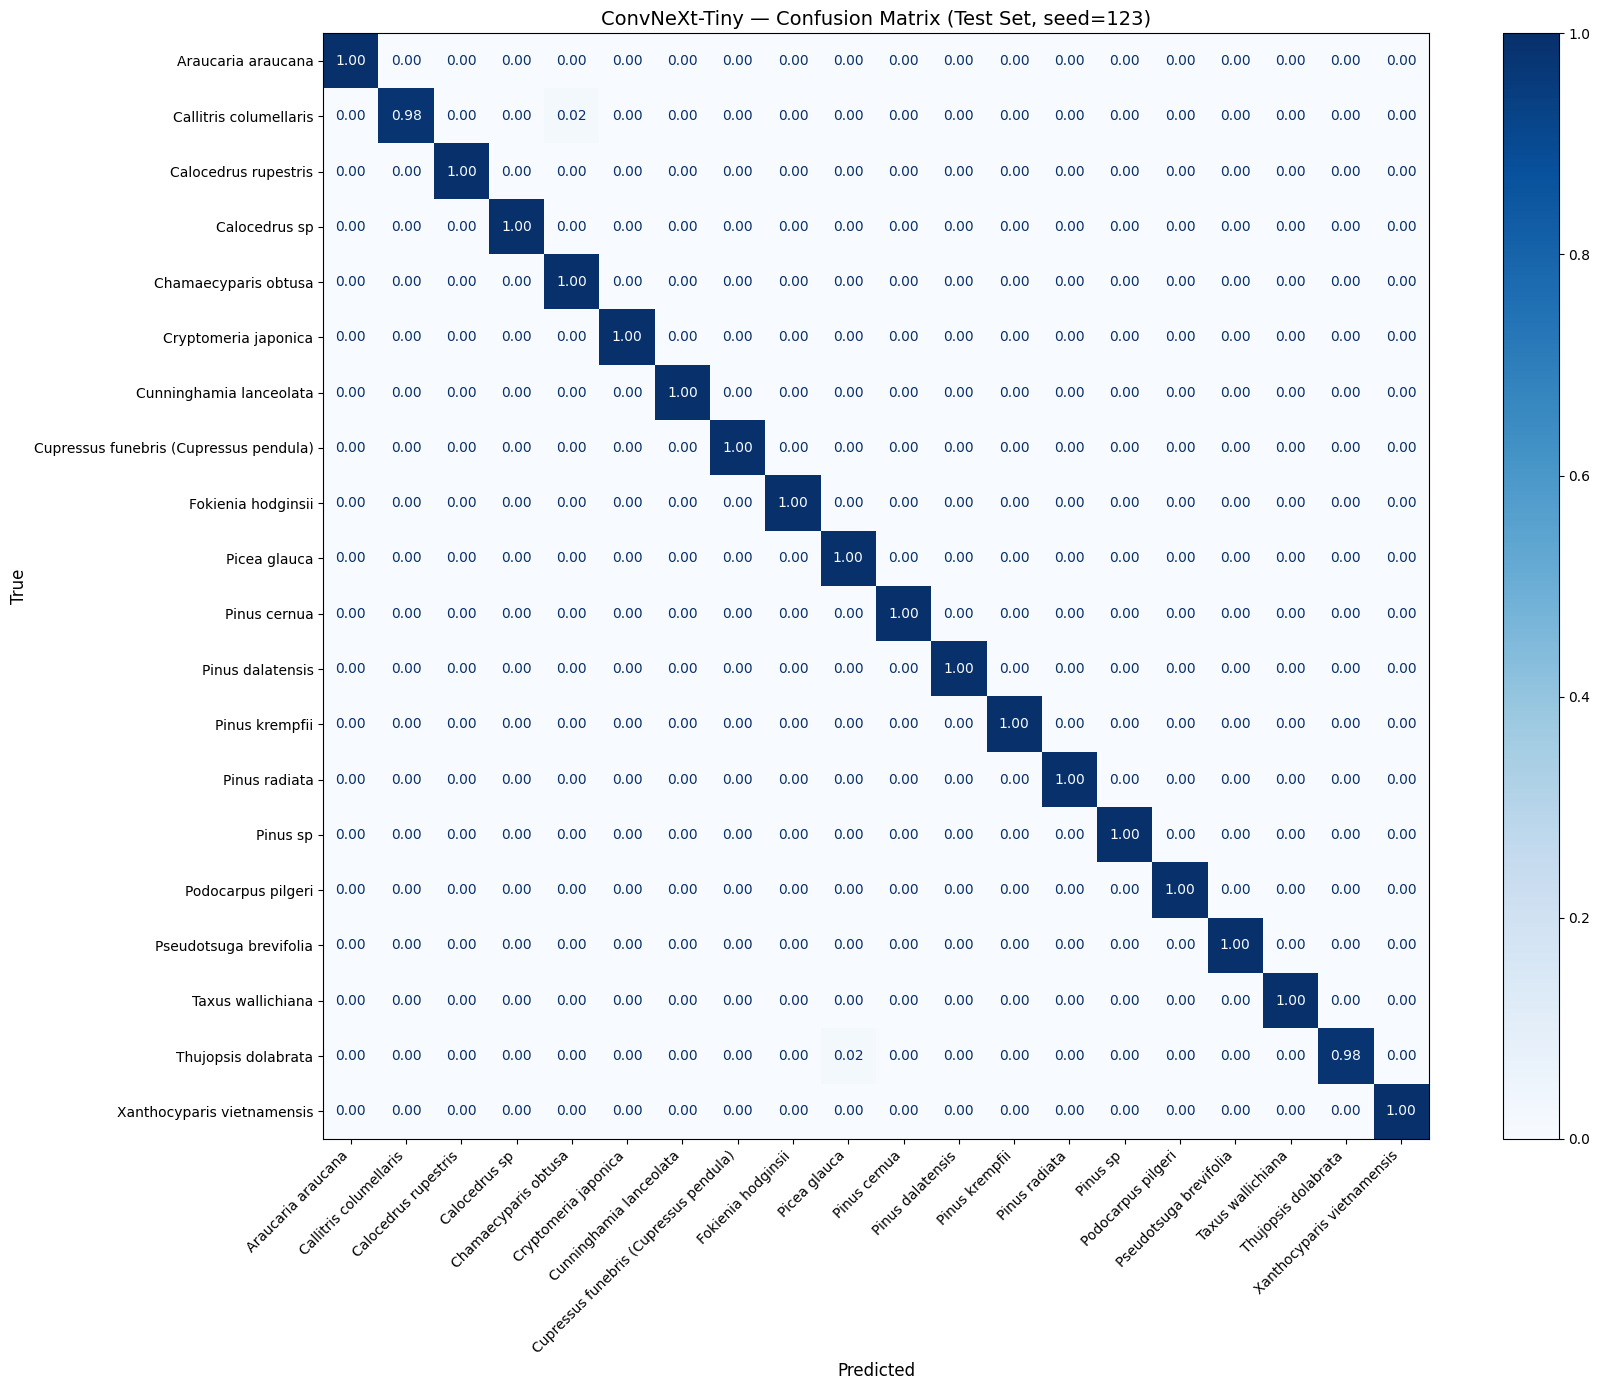


Classification Report (best seed = 123 )
                                        precision    recall  f1-score   support

                    Araucaria araucana       1.00      1.00      1.00        45
                Callitris columellaris       1.00      0.98      0.99        51
                  Calocedrus rupestris       1.00      1.00      1.00        45
                         Calocedrus sp       1.00      1.00      1.00        35
                  Chamaecyparis obtusa       0.98      1.00      0.99        48
                  Cryptomeria japonica       1.00      1.00      1.00        51
               Cunninghamia lanceolata       1.00      1.00      1.00        50
Cupressus funebris (Cupressus pendula)       1.00      1.00      1.00        48
                    Fokienia hodginsii       1.00      1.00      1.00        52
                          Picea glauca       0.98      1.00      0.99        45
                          Pinus cernua       1.00      1.00      1.00        

In [8]:
# ── Cell 8: Confusion Matrix + Test Metrics (all seeds) ──────────────────────
import torch, numpy as np, matplotlib.pyplot as plt, wandb
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.data import get_dataloaders

DATA_ROOT = ROOT / "data" / "task-B"
_ignored_train, _ignored_val, test_loader = get_dataloaders(
    str(DATA_ROOT), batch_size=32, num_workers=4, task="taskB"
)
class_names = test_loader.dataset.classes
num_classes = len(class_names)
print(f"[CM] {num_classes} classes: {class_names}")

all_preds, all_labels = {}, {}

for seed in SEEDS:
    backbone_dir = ROOT / "data" / "experiments" / "taskB" / "convnext_tiny" / f"seed_{seed}"

    ckpt_candidates = sorted(backbone_dir.glob("*best*.pth"))
    if not ckpt_candidates:
        print(f"[CM] No checkpoint found for seed={seed}, skipping")
        continue
    ckpt_path = ckpt_candidates[0]
    print(f"[CM] Loading: {ckpt_path}")

    from src.models import create_model

    model = create_model("convnext_tiny", num_classes=num_classes, pretrained=False)
    ckpt = torch.load(ckpt_path, map_location="cpu")
    model.load_state_dict(ckpt["model_state_dict"])
    model = model.to(DEVICE).eval()

    preds_s, labels_s = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            preds_s.extend(outputs.argmax(1).cpu().numpy())
            labels_s.extend(labels.numpy())
    all_preds[seed] = np.array(preds_s)
    all_labels[seed] = np.array(labels_s)

    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

    acc = accuracy_score(labels_s, preds_s)
    f1 = f1_score(labels_s, preds_s, average="macro", zero_division=0)
    prec = precision_score(labels_s, preds_s, average="macro", zero_division=0)
    rec = recall_score(labels_s, preds_s, average="macro", zero_division=0)
    print(f"[CM s{seed}] Acc={acc*100:.2f}%  F1={f1*100:.2f}%  Prec={prec*100:.2f}%  Rec={rec*100:.2f}%")

    f1_per = f1_score(labels_s, preds_s, average=None, zero_division=0)
    for cn, f in zip(class_names, f1_per):
        print(f"  {cn}: F1={f*100:.2f}%")

    wandb.init(
        project="woodbench-taskB",
        name=f"convnext_tiny_s{seed}_test",
        dir=str(backbone_dir),
    )
    wandb.log(
        {
            "test/accuracy": acc,
            "test/precision": prec,
            "test/recall": rec,
            "test/f1": f1,
            **{f"test/f1/{cn}": float(fi) for cn, fi in zip(class_names, f1_per)},
        }
    )
    wandb.finish()

# ── Confusion Matrix Plot ────────────────────────────────────────────────────
if not all_preds:
    raise RuntimeError("No checkpoints found — cannot plot confusion matrix")

best_seed = max(all_preds, key=lambda s: accuracy_score(all_labels[s], all_preds[s]))
y_true, y_pred = all_labels[best_seed], all_preds[best_seed]

fig, ax = plt.subplots(figsize=(18, 14))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=class_names,
    cmap="Blues", normalize="true", ax=ax, values_format=".2f",
)
ax.set_title(f"ConvNeXt-Tiny — Confusion Matrix (Test Set, seed={best_seed})", fontsize=14)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("True", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

cm_dir = ROOT / "data" / "experiments" / "taskB" / "convnext_tiny"
cm_path = cm_dir / "confusion_matrix.png"
fig.savefig(cm_path, dpi=150, bbox_inches="tight")
print(f"[CM] Saved to {cm_path}")

wandb.init(project="woodbench-taskB", name="convnext_tiny_CM", dir=str(cm_dir))
wandb.log({"confusion_matrix": wandb.Image(str(cm_path))})
wandb.finish()
plt.show()

print("\n" + "=" * 80)
print("Classification Report (best seed =", best_seed, ")")
print("=" * 80)
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

In [ ]:
import os, sys
print("PID:", os.getpid())
print("Python:", sys.executable)

PID: 3776
Python: /venv/main/bin/python


: 